# How-to 2 · A double-lined binary with TODCOR

Simulate 12 HARPS-like epochs of an SB2 (5800 K + 4900 K, light ratio 0.7 : 0.3), fit both
velocities and amplitudes per epoch with TODCOR, and compare with the injected truth.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sparta import CCF2d, Observations
from sparta.instruments import Simulation
from sparta.instruments.simulated import component_templates
from sparta.plotting import apply_style, mark_truth

apply_style()        # SPARTA figure style: data black, model red, extra blue, maps grey

In [2]:
# Circular orbit: period (d), semi-amplitudes and systemic velocity (km/s)
P, K1, K2, gamma = 4.3, 45.0, 75.0, 10.0                 # days, km/s, km/s, km/s
times = np.sort(np.random.default_rng(3).uniform(0, 20, 12))
# True RV of each star at each epoch
phase = 2 * np.pi * times / P
rv_true = np.column_stack([gamma + K1 * np.sin(phase), gamma - K2 * np.sin(phase)])

# The two stars observed like HARPS in one 200 Å order, S/N 50 per pixel
sim = Simulation(like="HARPS", windows_A=[(5000, 5200)], times=times, rv_kms=rv_true,
                 components=[dict(teff=5800, logg=3.5, feh=0.5, vsini=4.0, amplitude=0.7),
                             dict(teff=4900, logg=4.5, vsini=2.0, amplitude=0.3)],
                 snr=50, noise="constant", seed=4)
# Turn the simulation into an Observations object, as for real files
obs = Observations(survey="SIMULATED", simulation=sim)
t1, t2 = component_templates(sim)                        # the two rest-frame models
print(f"{obs.sample_size} epochs, frame {obs.wavelength_frame}, amplitudes {obs.truth.amplitudes}")

12 epochs, frame air, amplitudes [0.7 0.3]


In [3]:
# The log-λ step and the (v1, v2) grid: ±120 km/s every 2 km/s
settings = dict(dv=0.3, vel_bound=120, dvel=2.0)
# Fit every epoch with TODCOR: both velocities and both amplitudes
obs.calc_rv_against_two_templates(t1, t2, **settings)

# Compare each star's RVs with the injected truth
v1, v2 = obs.truth.rv_kms.T
for name, vel, err, truth in [("primary", obs.vels1, obs.evels1, v1),
                              ("secondary", obs.vels2, obs.evels2, v2)]:
    print(f"{name:9s}: rms(O-C) = {np.std(vel - truth) * 1e3:5.1f} m/s, "
          f"median error = {np.median(err) * 1e3:5.1f} m/s")
print(f"amplitudes: a1 = {obs.amps1.mean():.3f}, a2 = {obs.amps2.mean():.3f}  (truth 0.7, 0.3)")

primary  : rms(O-C) =   4.7 m/s, median error =   5.1 m/s
secondary: rms(O-C) =   7.9 m/s, median error =   8.8 m/s
amplitudes: a1 = 0.700, a2 = 0.300  (truth 0.7, 0.3)


The (v1, v2) correlation map R of epoch 0: the fit (red +) sits on the truth (blue ×) at the
crossing of the two stars' ridges.

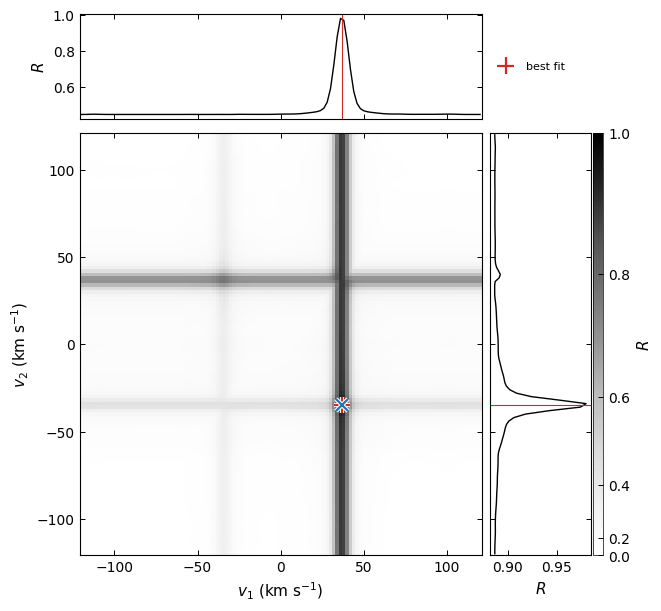

In [4]:
# Epoch 0's R map, with the injected truth marked
k = 0
fig = obs.ccf2d_list[k].plot()
mark_truth(fig.axes[0], v1[k], v2[k])
plt.show()

`output='loglike'` makes the profile log-likelihood the primary map (drawn as Δ ln L below the
peak); the velocities and errors are identical. At S/N 50 the peak is narrower than one 2 km/s
grid cell, so the map is nearly white away from it.

v1 = 36.8260 ± 0.0051 km/s (truth 36.8222); v2 = -34.7027 ± 0.0087 km/s (truth -34.7037)
same RVs as the R-map run: True


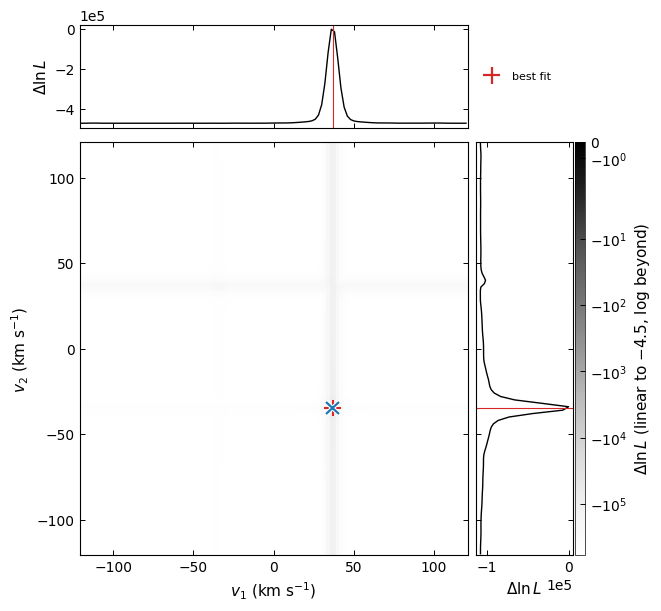

In [5]:
# The same epoch with the log-likelihood map as the primary output
fit = CCF2d().cross_correlate(obs.spec_list[k], t1, t2, output="loglike", **settings)
r = fit.Corr2d
print(f"v1 = {r['RV1']:.4f} ± {r['eRV1']:.4f} km/s (truth {v1[k]:.4f}); "
      f"v2 = {r['RV2']:.4f} ± {r['eRV2']:.4f} km/s (truth {v2[k]:.4f})")
# The RVs must not depend on the output
print("same RVs as the R-map run:", r["RV1"] == obs.vels1[k] and r["RV2"] == obs.vels2[k])
# The ΔlnL map, with the truth marked
fig = fit.plot()
mark_truth(fig.axes[0], v1[k], v2[k])
plt.show()

## Go deeper

- TODCOR built from its atoms, why its windows have no edge bias, and per-order light ratios: tutorial [`04_todcor`](../tutorials/04_todcor.ipynb).
- The model, the two maps and the Cramér–Rao errors: [correlation engines § TODCOR](../../docs/correlation_engines.md#todcor-ccf2d).
- Known limits: [limitations § TODCOR](../../docs/limitations.md#todcor).
- The standalone engine and its derivation: [`todcor_detailed/`](todcor_detailed/README.md).
- The checklist for TODCOR: [good practices](../../docs/good_practices.md#double-lined-binaries-todcor).